BREAST CANCER CLASSIFICATION
--------------------------------------------------
Dataset samples: 569
Number of features: 30
Target classes: 1 = Malignant, 0 = Benign

Class distribution:
Benign       357
Malignant    212
Name: count, dtype: int64

MODEL PERFORMANCE COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score  Training Time (s)  Prediction Time (s)
Logistic Regression    0.9649     0.9750  0.9286    0.9512             0.0782               0.0063
      Decision Tree    0.9211     0.9459  0.8333    0.8861             0.0305               0.0026
      Random Forest    0.9649     1.0000  0.9048    0.9500             0.4462               0.0144
           AdaBoost    0.9737     1.0000  0.9286    0.9630             0.7014               0.0687
    Voting Ensemble    0.9649     1.0000  0.9048    0.9500             1.7774               0.0718
  Stacking Ensemble    0.9912     1.0000  0.9762    0.9880             5.6413               0.0472


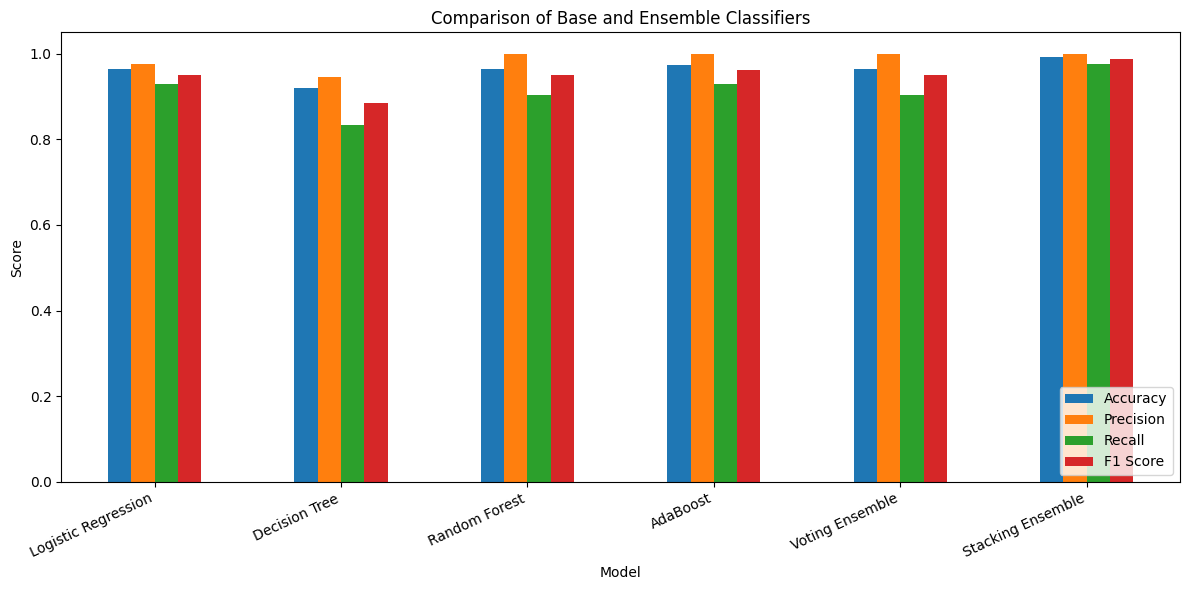

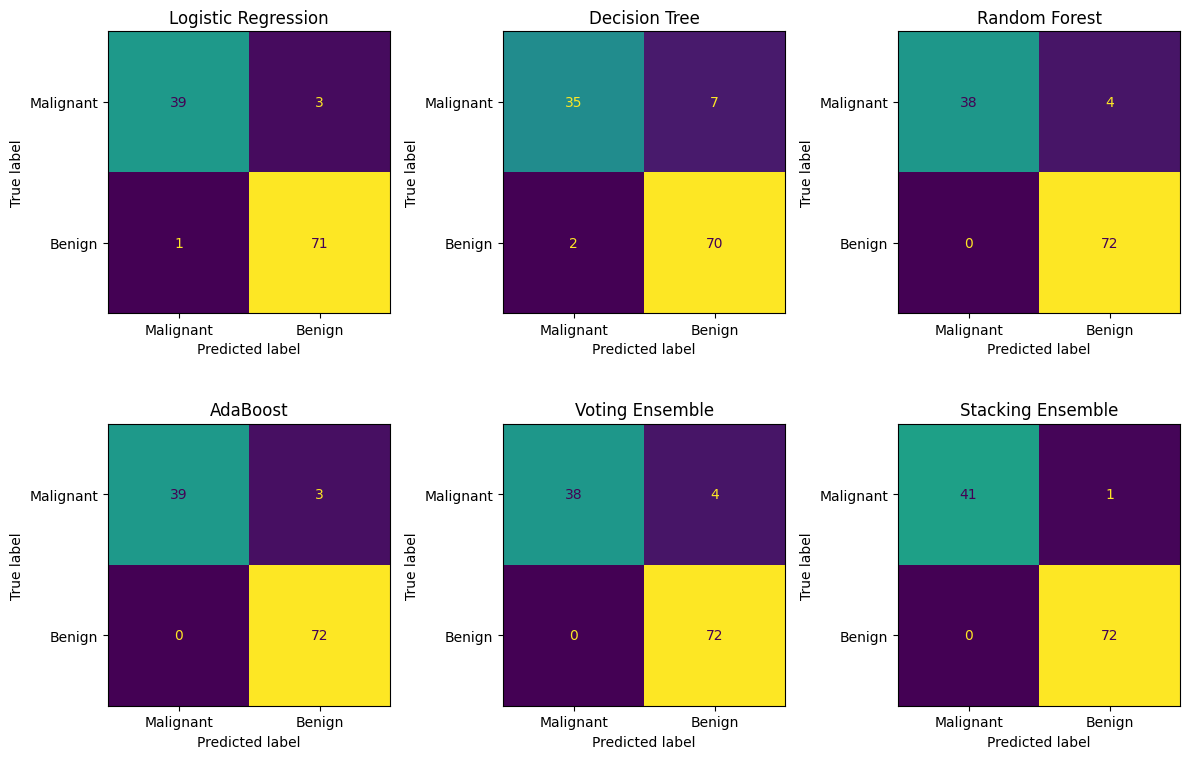


BEST MODEL BY F1 SCORE
Model: Stacking Ensemble
Accuracy: 0.9912
Precision: 1.0
Recall: 0.9762
F1 Score: 0.988

Files saved:
- ensemble_model_results.csv
- ensemble_metric_comparison.png
- ensemble_confusion_matrices.png


In [1]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    VotingClassifier,
    StackingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load the dataset
data = load_breast_cancer()

X = data.data

# Scikit-learn labels: 0 = malignant, 1 = benign
# Convert labels so malignant is the positive class (1).
y = (data.target == 0).astype(int)

print("BREAST CANCER CLASSIFICATION")
print("-" * 50)
print("Dataset samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes: 1 = Malignant, 0 = Benign")

print("\nClass distribution:")
print(pd.Series(y).value_counts().rename(
    index={1: "Malignant", 0: "Benign"}
))

# 2. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Define the base classifiers
logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

decision_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

random_forest = RandomForestClassifier(
    n_estimators=150,
    random_state=42
)

# 4. Define AdaBoost
# A decision stump is a tree with depth one.
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# 5. Define Voting Ensemble (majority voting)
voting = VotingClassifier(
    estimators=[
        ("lr", make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000, random_state=42)
        )),
        ("dt", DecisionTreeClassifier(
            max_depth=5, random_state=42
        )),
        ("rf", RandomForestClassifier(
            n_estimators=150, random_state=42
        ))
    ],
    voting="hard"
)

# 6. Define Stacking Ensemble
stacking = StackingClassifier(
    estimators=[
        ("lr", make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000, random_state=42)
        )),
        ("dt", DecisionTreeClassifier(
            max_depth=5, random_state=42
        )),
        ("rf", RandomForestClassifier(
            n_estimators=150, random_state=42
        ))
    ],
    final_estimator=LogisticRegression(
        max_iter=5000, random_state=42
    ),
    cv=5
)

# 7. Combine all models for evaluation
models = {
    "Logistic Regression": logistic,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "AdaBoost": ada,
    "Voting Ensemble": voting,
    "Stacking Ensemble": stacking
}

results = []
confusion_matrices = {}

# 8. Train and evaluate each model
for name, model in models.items():

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    start_time = time.perf_counter()

    y_pred = model.predict(X_test)

    prediction_time = time.perf_counter() - start_time

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

    confusion_matrices[name] = confusion_matrix(
        y_test, y_pred, labels=[1, 0]
    )

# 9. Display comparison table
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))

# Save the results
results_df.to_csv(
    "ensemble_model_results.csv",
    index=False
)

# 10. Plot metric comparison
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Base and Ensemble Classifiers")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("ensemble_metric_comparison.png", dpi=150)
plt.show()

# 11. Display confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (name, cm) in zip(
    axes.flat, confusion_matrices.items()
):
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Malignant", "Benign"]
    )
    display.plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.savefig("ensemble_confusion_matrices.png", dpi=150)
plt.show()

# 12. Identify the model with the highest F1 score
best_index = results_df["F1 Score"].idxmax()
best_model = results_df.loc[best_index]

print("\nBEST MODEL BY F1 SCORE")
print("Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))

print("\nFiles saved:")
print("- ensemble_model_results.csv")
print("- ensemble_metric_comparison.png")
print("- ensemble_confusion_matrices.png")
